In [6]:
import qiskit
from qiskit import * #qiskit
from qiskit.visualization import plot_histogram, plot_distribution
from qiskit.quantum_info import SparsePauliOp

import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline

import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
import time
import copy

In [7]:
# Utilities are organized in the cells below.

In [8]:
from qiskit_aer import AerSimulator


def Rxyz(qc, qr, n1, n2, tx, ty, tz):
    """Apply exp[-i(tx XX + ty YY + tz ZZ)/2] to two qubits."""
    qc.cx(qr[n2], qr[n1])
    qc.rz(tz, qr[n1])
    qc.h(qr[n2])
    qc.rz(tx + np.pi / 2, qr[n2])
    qc.cx(qr[n2], qr[n1])
    qc.rz(-ty, qr[n1])
    qc.h(qr[n2])
    qc.cx(qr[n2], qr[n1])
    qc.rx(np.pi / 2, qr[n1])
    qc.rx(-np.pi / 2, qr[n2])


def Rxxz(qc, qr, n1, n2, tx, tz):
    Rxyz(qc, qr, n1, n2, tx, tx, tz)


def Rxxx(qc, qr, n1, n2, tx):
    Rxyz(qc, qr, n1, n2, tx, tx, tx)


def _simulate_counts(shots, circuits):
    backend = AerSimulator()
    for index, circuit in enumerate(circuits):
        start_time = time.time()
        result = backend.run(circuit, shots=shots).result()
        counts = result.get_counts(circuit)
        yield index, circuit, counts, time.time() - start_time


def _report_simulation(index, circuit, elapsed):
    print(f"{index}-th iteration running time: {elapsed} seconds. QC depth: {circuit.depth()}")


def _diagonal_expectation(weights, diagonal, shots=None):
    expectation = sum(
        diagonal[int(bitstring[::-1], 2)] * weight
        for bitstring, weight in weights.items()
    )
    return expectation if shots is None else expectation / float(shots)


def _neel_expectation(counts, n_site, shots, normalize=True):
    expectation = 0.0
    for bitstring, count in counts.items():
        ordered_bits = bitstring[::-1]
        observable = sum(
            (-1) ** int(ordered_bits[site]) * (-1) ** (site + 1)
            for site in range(n_site)
        )
        expectation += observable * count / float(shots)
    return expectation / (2 * n_site) if normalize else expectation

In [9]:
def computeExpectationNeelSim(shots, qc_list, counts_list, diag, expList):
    for index, circuit, counts, elapsed in _simulate_counts(shots, qc_list):
        counts_list.append(counts)
        expList.append(_diagonal_expectation(counts, diag, shots))
        _report_simulation(index, circuit, elapsed)


def computeExpectationCountDevice(shots, counts_list, diag, expList):
    for counts in counts_list:
        expList.append(_diagonal_expectation(counts, diag, shots))


def computeExpectationDistributionDevice(distribution_list, diag, expList):
    for distribution in distribution_list:
        expList.append(_diagonal_expectation(distribution, diag))


def computeExpectationDistirubtionDevice(distribution_list, diag, expList):
    """Backward-compatible wrapper for the original misspelled public name."""
    computeExpectationDistributionDevice(distribution_list, diag, expList)


def computeNeelsExpectationDevice(shots, count, n_site):
    return _neel_expectation(count, n_site, shots=shots)


def computeNeelsExpectationListDevice(shots, counts_list, expList, n_site):
    for counts in counts_list:
        expList.append(_neel_expectation(counts, n_site, shots=shots))


def computeExpectationNeelSimNoDiag(
    shots, qc_list, counts_list, expList, n_site, norm=True
):
    for index, circuit, counts, elapsed in _simulate_counts(shots, qc_list):
        counts_list.append(counts)
        expList.append(
            _neel_expectation(counts, n_site, shots=shots, normalize=norm)
        )
        _report_simulation(index, circuit, elapsed)

In [10]:
def _transition_probabilities(shots, counts, bitstrings):
    return tuple(counts.get(bitstring[::-1], 0) / shots for bitstring in bitstrings)


def _dimer_probability(shots, counts, dimer_bitstrings):
    total = sum(counts.get(bitstring[::-1], 0) for bitstring in dimer_bitstrings)
    return total / float(shots)


def _is_dimer_configuration(bitstring, n_site=None):
    n_site = len(bitstring) if n_site is None else n_site
    return all(bitstring[i] != bitstring[i + 1] for i in range(0, n_site, 2))


def _new_dimer_probability(shots, counts, n_site=None):
    total = sum(
        count
        for bitstring, count in counts.items()
        if _is_dimer_configuration(bitstring, n_site)
    )
    return total / float(shots)


def computeTransitionProbDevice(shots, counts, NeelString, DWString, S2String, S4String):
    return _transition_probabilities(
        shots, counts, (NeelString, DWString, S2String, S4String)
    )


def computeTransitionProbListDevice(
    shots, counts_list, Neel, DW, S2, S4, NeelList, DWList, S2List, S4List
):
    output_lists = (NeelList, DWList, S2List, S4List)
    for counts in counts_list:
        probabilities = _transition_probabilities(shots, counts, (Neel, DW, S2, S4))
        for output, probability in zip(output_lists, probabilities):
            output.append(probability)


def computeNeelTransitionProbSim(
    shots, qc_list, counts_list, Neel, DW, S2, S4,
    NeelList, DWList, S2List, S4List
):
    output_lists = (NeelList, DWList, S2List, S4List)
    for index, circuit, counts, elapsed in _simulate_counts(shots, qc_list):
        counts_list.append(counts)
        probabilities = _transition_probabilities(shots, counts, (Neel, DW, S2, S4))
        for output, probability in zip(output_lists, probabilities):
            output.append(probability)
        _report_simulation(index, circuit, elapsed)


def computeDimerMeasureSim(shots, qc_list, counts_list, Dimer_bitstring, Dimer_list):
    for index, circuit, counts, elapsed in _simulate_counts(shots, qc_list):
        counts_list.append(counts)
        Dimer_list.append(_dimer_probability(shots, counts, Dimer_bitstring))
        _report_simulation(index, circuit, elapsed)


def computeDimerMeasureSimNew(shots, qc_list, counts_list, Dimer_list):
    for index, circuit, counts, elapsed in _simulate_counts(shots, qc_list):
        counts_list.append(counts)
        Dimer_list.append(_new_dimer_probability(shots, counts))
        _report_simulation(index, circuit, elapsed)

In [11]:
def computeDimerMeasureDevice(shots, counts, Dimer_bitstring):
    return _dimer_probability(shots, counts, Dimer_bitstring)


def computeDimerMeasureDeviceNew(shots, counts, N):
    return _new_dimer_probability(shots, counts, n_site=N)


def computeDimerMeasureListDevice(shots, counts_list, Dimer_bitstring, Dimer_list):
    for counts in counts_list:
        Dimer_list.append(_dimer_probability(shots, counts, Dimer_bitstring))


def computeDimerMeasureListDeviceNew(shots, counts_list, Dimer_list):
    for counts in counts_list:
        Dimer_list.append(_new_dimer_probability(shots, counts))


def _prepare_initial_state(qc, qr, init_state):
    n_site = len(qr)
    midpoint = n_site // 2

    if init_state == "Neel":
        for site in range(1, n_site, 2):
            qc.x(qr[site])
    elif init_state == "DW":
        for site in range(midpoint):
            if site % 2 == 1:
                qc.x(qr[site])
        for site in range(midpoint, n_site):
            if site % 2 == 0:
                qc.x(qr[site])
    elif init_state == "DW1":
        for site in range(midpoint, n_site):
            qc.x(qr[site])
    elif init_state == "DW2":
        for site in range(midpoint):
            qc.x(qr[site])
    elif init_state == "S2":
        for site in range(1, midpoint - 2, 2):
            qc.x(qr[site])
        qc.x(qr[midpoint])
        qc.x(qr[midpoint + 1])
        for site in range(midpoint + 2, n_site):
            if site % 2 == 1:
                qc.x(qr[site])
    elif init_state == "S4":
        for site in range(1, midpoint - 4, 2):
            qc.x(qr[site])
        for site in (midpoint - 2, midpoint - 1, midpoint + 2, midpoint + 3):
            qc.x(qr[site])
        for site in range(midpoint + 4, n_site):
            if site % 2 == 1:
                qc.x(qr[site])
    elif init_state == "Dimer":
        qc.x(qr)
        for site in range(0, n_site, 2):
            qc.h(qr[site])
            qc.cx(qr[site], qr[site + 1])


def _new_evolution_circuit(n_site, init_state, barrier, measurement=True):
    qr = QuantumRegister(n_site, "q")
    cr = ClassicalRegister(n_site, "c")
    qc = QuantumCircuit(qr)
    if measurement:
        qc.add_register(cr)
    _prepare_initial_state(qc, qr, init_state)
    if barrier:
        qc.barrier()
    return qc, qr, cr

In [12]:
def _apply_bond(qc, qr, left, right, model, xy_angle, z_angle=None):
    if model == "XXX":
        Rxxx(qc, qr, left, right, xy_angle)
    else:
        Rxxz(qc, qr, left, right, xy_angle, z_angle)


def _apply_even_layer(qc, qr, model, xy_angle, z_angle=None):
    for left in range(0, len(qr) - 1, 2):
        _apply_bond(qc, qr, left, left + 1, model, xy_angle, z_angle)


def _apply_odd_layer(qc, qr, model, xy_angle, z_angle=None, PBC=True):
    for left in range(1, len(qr) - 1, 2):
        _apply_bond(qc, qr, left, left + 1, model, xy_angle, z_angle)
    if PBC:
        _apply_bond(qc, qr, len(qr) - 1, 0, model, xy_angle, z_angle)


def _apply_first_order_step(qc, qr, model, dt, j1, delta, barrier, PBC):
    xy_angle = 0.5 * j1 * dt
    z_angle = None if model == "XXX" else 0.5 * delta * dt
    _apply_even_layer(qc, qr, model, xy_angle, z_angle)
    _apply_odd_layer(qc, qr, model, xy_angle, z_angle, PBC)
    if barrier:
        qc.barrier()


def _generate_first_order(N, T, dt, j1, delta, init_state, barrier, PBC, model):
    circuits = []
    for step_index in range(int(T / dt)):
        start_time = time.time()
        qc, qr, cr = _new_evolution_circuit(N, init_state, barrier)
        for _ in range(step_index + 1):
            _apply_first_order_step(qc, qr, model, dt, j1, delta, barrier, PBC)
        qc.measure(qr, cr)
        circuits.append(qc)
        print("qc Depth: ", qc.depth())
        print(f"{step_index}-th iteration running time: {time.time() - start_time} seconds.")
    return circuits


def generate_time_evolution_XXX(
    N, T, dt, j1, init_state="Neel", barrier=True, PBC=True
):
    return _generate_first_order(
        N, T, dt, j1, None, init_state, barrier, PBC, model="XXX"
    )


def generate_time_evolution_XXZ(
    N, T, dt, j1, delta, init_state="Neel", barrier=True, PBC=True
):
    return _generate_first_order(
        N, T, dt, j1, delta, init_state, barrier, PBC, model="XXZ"
    )

In [13]:
def _apply_second_order_evolution(
    qc, qr, steps, model, dt, j1, delta, barrier, PBC
):
    even_xy = 0.25 * j1 * dt
    full_xy = 0.5 * j1 * dt
    even_z = None if model == "XXX" else 0.25 * delta * dt
    full_z = None if model == "XXX" else 0.5 * delta * dt

    _apply_even_layer(qc, qr, model, even_xy, even_z)
    _apply_odd_layer(qc, qr, model, full_xy, full_z, PBC)
    if barrier:
        qc.barrier()

    for _ in range(steps - 1):
        _apply_even_layer(qc, qr, model, full_xy, full_z)
        _apply_odd_layer(qc, qr, model, full_xy, full_z, PBC)
        if barrier:
            qc.barrier()

    _apply_even_layer(qc, qr, model, even_xy, even_z)
    if barrier:
        qc.barrier()


def _generate_second_order(
    N, T, dt, j1, delta, init_state, barrier, PBC, measurement, model
):
    circuits = []
    for step_index in range(int(T / dt)):
        start_time = time.time()
        qc, qr, cr = _new_evolution_circuit(N, init_state, barrier, measurement)
        _apply_second_order_evolution(
            qc, qr, step_index + 1, model, dt, j1, delta, barrier, PBC
        )
        if measurement:
            qc.measure(qr, cr)
        circuits.append(qc)
        print("qc Depth: ", qc.depth())
        print(f"{step_index}-th iteration running time: {time.time() - start_time} seconds.")
    return circuits


def generate_time_evolution_XXX_2nd(
    N, T, dt, j1, init_state="Neel", barrier=True, PBC=True
):
    return _generate_second_order(
        N, T, dt, j1, None, init_state, barrier, PBC, True, model="XXX"
    )


def generate_time_evolution_XXZ_2nd(
    N, T, dt, j1, delta, init_state="Neel", barrier=True, PBC=True,
    measurement=True
):
    return _generate_second_order(
        N, T, dt, j1, delta, init_state, barrier, PBC, measurement, model="XXZ"
    )

In [14]:
def _apply_self_qem_evolution(qc, qr, step_index, dt, j1, delta, barrier, PBC):
    _apply_even_layer(qc, qr, "XXZ", 0.25 * j1 * dt, 0.25 * delta * dt)
    _apply_odd_layer(qc, qr, "XXZ", 0.5 * j1 * dt, 0.5 * delta * dt, PBC)
    if barrier:
        qc.barrier()

    midpoint = step_index // 2
    for layer_index in range(step_index):
        if layer_index == midpoint:
            even_dt, odd_dt = 0.0, -dt
        else:
            layer_dt = dt if layer_index < step_index / 2 else -dt
            even_dt = odd_dt = layer_dt
        _apply_even_layer(
            qc, qr, "XXZ", 0.5 * j1 * even_dt, 0.5 * delta * even_dt
        )
        _apply_odd_layer(
            qc, qr, "XXZ", 0.5 * j1 * odd_dt, 0.5 * delta * odd_dt, PBC
        )
        if barrier:
            qc.barrier()

    _apply_even_layer(qc, qr, "XXZ", -0.25 * j1 * dt, -0.25 * delta * dt)
    if barrier:
        qc.barrier()


def generate_time_evolution_XXZ_selfQEM(
    N, T, dt, j1, delta, init_state="Neel", barrier=True, PBC=True,
    measurement=True
):
    circuits = []
    for step_index in range(int(T / dt)):
        if (step_index + 1) % 2 == 1:
            continue
        start_time = time.time()
        qc, qr, cr = _new_evolution_circuit(N, init_state, barrier, measurement)
        _apply_self_qem_evolution(
            qc, qr, step_index, dt, j1, delta, barrier, PBC
        )
        if measurement:
            qc.measure(qr, cr)
        circuits.append(qc)
        print("qc Depth: ", qc.depth())
        print(f"{step_index}-th iteration running time: {time.time() - start_time} seconds.")
    return circuits

In [15]:
qiskit.__version__

'2.5.1'

# XXZ with Open BC

In [16]:
j1, j2, Delta = 1.0, 0.0, 0.5 # Point B

In [28]:
N = 20 # Lattice Size
T = 5.0
dt = 0.01

In [18]:
x_exact = [dt*(s+1) for s in range(int(T/dt))]

In [19]:
len(x_exact)

500

In [20]:
print(x_exact, )

[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3, 0.31, 0.32, 0.33, 0.34, 0.35000000000000003, 0.36, 0.37, 0.38, 0.39, 0.4, 0.41000000000000003, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47000000000000003, 0.48, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.5700000000000001, 0.58, 0.59, 0.6, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.6900000000000001, 0.7000000000000001, 0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.8, 0.81, 0.8200000000000001, 0.8300000000000001, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9, 0.91, 0.92, 0.93, 0.9400000000000001, 0.9500000000000001, 0.96, 0.97, 0.98, 0.99, 1.0, 1.01, 1.02, 1.03, 1.04, 1.05, 1.06, 1.07, 1.08, 1.09, 1.1, 1.11, 1.12, 1.1300000000000001, 1.1400000000000001, 1.1500000000000001, 1.16, 1.17, 1.18, 1.19, 1.2, 1.21, 1.22, 1.23, 1.24, 1.25, 1.26, 1.27, 1.28, 1.29, 1.3, 1.31, 1.32, 1.33, 1.34, 1.35, 1.36, 1.37, 1.38

In [21]:
#start_time_T = time.time()
#psi0 = ground_state(H)
#print(f"Total running time: {(time.time() - start_time_T)} seconds.")    
psi0 = np.zeros(2**N)
Neel_bitstring       = '01010101010101010101'
DW_bitstring         = '01010101011010101010'
TwoSpinon_bitstring  = '01010101001101010101'
FourSpinon_bitstring = '01010100110011010101'

psi0[int(Neel_bitstring, 2)] = 1.0

# QuSpin

In [22]:
import quspin
from quspin.operators import hamiltonian,exp_op
from quspin.basis import spinful_fermion_basis_general
from quspin.basis import spin_basis_1d
from quspin.basis import spinless_fermion_basis_1d
from quspin.basis import tensor_basis
from quspin.tools.measurements import ent_entropy

from quspin.tools.evolution import evolve
from quspin.tools.Floquet import Floquet_t_vec 

In [23]:
def XXZ(L, j1, delta):
    interact_xx = [[0.25*j1, j, j+1] for j in range(int(N)-1)]
    interact_zz = [[0.25*delta, j, j+1] for j in range(int(N)-1)]
    
    basis = spin_basis_1d(L)

    # Define Hamiltonian
    static = [["xx", interact_xx],["yy", interact_xx],["zz", interact_zz]]
    dynamic = []
    H = hamiltonian(static,dynamic,basis=basis,dtype=np.complex128, check_symm=False,check_herm=False,check_pcon=False)
    
    return H

In [24]:
def obsStagMag(N):
    h_z = [[(-1)**(n+1)/(2*N),n] for n in range(N)]
  
    basis = spin_basis_1d(N)

    # Define Hamiltonian
    static = [["z",h_z]]

    dynamic = []
    H = hamiltonian(static,dynamic,basis=basis,dtype=np.complex128, check_symm=False,check_herm=False,check_pcon=False)
    
    return H

In [27]:
Ham = XXZ(N, j1, Delta)
obs_quspin = obsStagMag(N)
exp_quspin = []
it = 0
start_time_T = time.time()
for t in x_exact:
    it = it+1
    start_time = time.time()    
    psi=exp_op(Ham,a=-1j*t).dot(psi0)
    psi1=obs_quspin.dot(psi)    
    value=np.dot(np.conjugate(psi),psi1).real
    exp_quspin.append(value)
    print(f"{it}-th iteration running time: {(time.time() - start_time)} seconds.")
print(f"Total running time: {(time.time() - start_time_T)} seconds.")

1-th iteration running time: 0.7131319046020508 seconds.
2-th iteration running time: 0.5479490756988525 seconds.
3-th iteration running time: 1.6596670150756836 seconds.
4-th iteration running time: 0.75541090965271 seconds.
5-th iteration running time: 0.5676751136779785 seconds.
6-th iteration running time: 0.5675599575042725 seconds.
7-th iteration running time: 0.6046357154846191 seconds.
8-th iteration running time: 0.5982949733734131 seconds.
9-th iteration running time: 0.6673531532287598 seconds.
10-th iteration running time: 0.7184000015258789 seconds.
11-th iteration running time: 0.691277265548706 seconds.
12-th iteration running time: 0.7133350372314453 seconds.
13-th iteration running time: 0.6474878787994385 seconds.
14-th iteration running time: 0.6904127597808838 seconds.
15-th iteration running time: 0.7124316692352295 seconds.
16-th iteration running time: 0.6753132343292236 seconds.
17-th iteration running time: 0.7016277313232422 seconds.


KeyboardInterrupt: 

In [ ]:
len(exp_quspin)

0

In [ ]:
print(exp_quspin, )

[]


In [ ]:
exp_quspin = [-0.4999525012369588, -0.4998100197906511, -0.4995726001839232, -0.49924031660254087, -0.498813272867376, -0.4982916023946571, -0.4976754681455553, -0.49696506256411577, -0.49616060750441787, -0.4952623541463133, -0.4942705828999673, -0.49318560329976724, -0.49200775388698337, -0.4907374020809955, -0.4893749440403562, -0.4879208045128708, -0.48637543667432925, -0.48473932195720215, -0.483012969868407, -0.4811969177965727, -0.4792917308087168, -0.47729800143690154, -0.47521634945434943, -0.4730474216413378, -0.4707918915411964, -0.4684504592067142, -0.46602385093549314, -0.46351281899725644, -0.4609181413499956, -0.45824062134793225, -0.45548108743921595, -0.4526403928548835, -0.44971941528864307, -0.4467190565676352, -0.4436402423148909, -0.4404839216022321, -0.4372510665956907, -0.4339426721921757, -0.430559755647717, -0.42710335619836376, -0.4235745346726541, -0.41997437309682534, -0.4163039742923506, -0.4125644614664405, -0.4087569777948752, -0.40488268599853194, -0.4009427679128927, -0.39693842405080637, -0.39287087315906866, -0.38874135176910396, -0.38455111374094825, -0.3803014298022074, -0.37599358708082053, -0.3716288886328725, -0.36720865296497, -0.36273421355167795, -0.35820691834830454, -0.35362812929896703, -0.3489992218403324, -0.3443215844013677, -0.3395966178988921, -0.3348257352297194, -0.33001036075896706, -0.32515192980531604, -0.320251888123091, -0.31531169138155773, -0.31033280464144625, -0.30531670182917653, -0.3002648652088591, -0.2951787848522495, -0.2900599581069917, -0.284909889063279, -0.2797300880192102, -0.2745220709449951, -0.2692873589462904, -0.2640274777268943, -0.2587439570508846, -0.25343833020462164, -0.2481121334586694, -0.2427669055299102, -0.23740418704403887, -0.2320255199987487, -0.2266324472276575, -0.2212265118653306, -0.21580925681356072, -0.21038222420907027, -0.20494695489288, -0.19950498788162463, -0.1940578598408611, -0.18860710456068994, -0.18315425243386305, -0.17770082993657113, -0.1722483591121471, -0.16679835705773266, -0.1613523354143366, -0.15591179986031647, -0.1504782496084459, -0.14505317690691083, -0.13963806654423624, -0.13423439535848658, -0.12884363175080102, -0.123467235203503, -0.11810665580293729, -0.11276333376720472, -0.10743869897897945, -0.10213417052355443, -0.09685115623228853, -0.09159105223161496, -0.08635524249776243, -0.08114509841736246, -0.07596197835405986, -0.07080722722130971, -0.06568217606147404, -0.06058814163139777, -0.055526425994550925, -0.05049831611992312, -0.04550508348777354, -0.04054798370236539, -0.03562825611182195, -0.03074712343521269, -0.025905791396995944, -0.02110544836893157, -0.016347265019568284, -0.011632393971420088, -0.006961969465929854, -0.0023371070363295936, 0.0022410968115253033, 0.006771564910228281, 0.011253239733739092, 0.0156850836920377, 0.020066079417449346, 0.02439523004255463, 0.028671559469609552, 0.03289411263141389, 0.037061955743548126, 0.04117417654792855, 0.045229884547609955, 0.04922821123279449, 0.05316831029797671, 0.057049357850195215, 0.060870552608329076, 0.06463111609341965, 0.06833029280995713, 0.07196735041812079, 0.07554157989692722, 0.07905229569826763, 0.08249883589181979, 0.08588056230080207, 0.08919686062856327, 0.09244714057600172, 0.09563083594979561, 0.09874740476144972, 0.10179632931715714, 0.10477711629847979, 0.10768929683384941, 0.11053242656091028, 0.11330608567970828, 0.11600987899675777, 0.11864343595998535, 0.12120641068459995, 0.1236984819699014, 0.12611935330706822, 0.12846875287795143, 0.1307464335449256, 0.1329521728318241, 0.13508577289600418, 0.13714706049162032, 0.13913588692410608, 0.14105212799596567, 0.14289568394390562, 0.1446664793673706, 0.14636446314857626, 0.14798960836404482, 0.1495419121877909, 0.15102139578615664, 0.15242810420442826, 0.15376210624527958, 0.15502349433913198, 0.15621238440653018, 0.15732891571258273, 0.15837325071361216, 0.15934557489605206, 0.1602460966077182, 0.16107504688153457, 0.16183267925183747, 0.16251926956332868, 0.16313511577279166, 0.16368053774370264, 0.16415587703380702, 0.16456149667579123, 0.16489778095117077, 0.16516513515749168, 0.1653639853689733, 0.16549477819070763, 0.16555798050655257, 0.16555407922079515, 0.16548358099377725, 0.1653470119715556, 0.16514491750974547, 0.1648778618916757, 0.16454642804098243, 0.16415121722879847, 0.1636928487756254, 0.16317195974805954, 0.1625892046505195, 0.16194525511205693, 0.16124079956846368, 0.16047654293976749, 0.1596532063032547, 0.1587715265621935, 0.15783225611039498, 0.1568361624927238, 0.1557840280617491, 0.15467664963064642, 0.15351483812252753, 0.152299418216308, 0.15103122798930424, 0.1497111185566931, 0.14833995370793066, 0.14691860954040092, 0.14544797409031063, 0.1439289469610623, 0.142362438949248, 0.14074937166837553, 0.13909067717052737, 0.13738729756607013, 0.13564018464157526, 0.1338502994760975, 0.13201861205598497, 0.13014610088833486, 0.12823375261327277, 0.1262825616151951, 0.12429352963313157, 0.12226766537036524, 0.1202059841034634, 0.11810950729088696, 0.11597926218129395, 0.1138162814217029, 0.11162160266566735, 0.10939626818159764, 0.10714132446136924, 0.10485782182938658, 0.102546814052214, 0.10020935794894226, 0.09784651300242289, 0.09545934097149571, 0.09304890550438155, 0.09061627175334826, 0.08816250599080223, 0.0856886752269384, 0.08319584682907435, 0.08068508814282536, 0.07815746611522059, 0.07561404691991541, 0.0730558955846215, 0.07048407562086847, 0.06789964865625206, 0.06530367406926299, 0.0626972086268375, 0.06008130612474388, 0.05745701703092334, 0.05482538813190847, 0.05218746218243358, 0.04954427755833379, 0.04689686791287758, 0.04424626183661585, 0.04159348252086191, 0.03893954742491687, 0.03628546794713704, 0.03363224909994314, 0.03098088918888088, 0.02833237949582544, 0.02568770396642289, 0.02304783890186549, 0.02041375265509649, 0.017786405331526745, 0.015166748494351944, 0.012555724874562066, 0.009954268085716757, 0.007363302343571345, 0.004783742190633506, 0.002216492225722901, -0.0003375531613896716, -0.002877510050195587, -0.005402505244441729, -0.007911676521840362, -0.010404172878430472, -0.012879154767524607, -0.015335794333192848, -0.017773275638213588, -0.020190794886445776, -0.022587560639567652, -0.02496279402813227, -0.027315728956892476, -0.02964561230435157, -0.03195170411649642, -0.034233277794675374, -0.03648962027757773, -0.03872003221728599, -0.040923828149370414, -0.04310033665698276, -0.045248900528942634, -0.04736887691176742, -0.049459637455640304, -0.0515205684542967, -0.053551070978791984, -0.05555056100516489, -0.05751846953595274, -0.05945424271556913, -0.06135734193953467, -0.06322724395753815, -0.06506344097034483, -0.06686544072053847, -0.0686327665771025, -0.0703649576138472, -0.07206156868167693, -0.07372217047472318, -0.0753463495903374, -0.07693370858296573, -0.07848386601192237, -0.07999645648306995, -0.0814711306844278, -0.08290755541574953, -0.08430541361205166, -0.08566440436116944, -0.08698424291533062, -0.0882646606967932, -0.08950540529757006, -0.09070624047329243, -0.09186694613122667, -0.09298731831250096, -0.0940671691685621, -0.09510632693193208, -0.09610463588127494, -0.09706195630085891, -0.09797816443441225, -0.09885315243347914, -0.09968682830028139, -0.1004791158251571, -0.10122995451863635, -0.10193929953819228, -0.10260712160975871, -0.10323340694402287, -0.10381815714761727, -0.10436138912921085, -0.10486313500061537, -0.10532344197294505, -0.10574237224790103, -0.10612000290425282, -0.10645642577958889, -0.1067517473474091, -0.10700608858961219, -0.10721958486448738, -0.10739238577026274, -0.1075246550042769, -0.10761657021788242, -0.10766832286713827, -0.10768011805937222, -0.10765217439570134, -0.10758472380959598, -0.1074780114015492, -0.10733229526997301, -0.10714784633835436, -0.10692494817882714, -0.10666389683215556, -0.10636500062431448, -0.10602857997967945, -0.10565496723094983, -0.10524450642589332, -0.10479755313098807, -0.10431447423206658, -0.10379564773205296, -0.10324146254587405, -0.10265231829263945, -0.10202862508519804, -0.10137080331714625, -0.10067928344739703, -0.09995450578237434, -0.09919692025598177, -0.09840698620737245, -0.09758517215666684, -0.0967319555786959, -0.0958478226748615, -0.09493326814320577, -0.0939887949467947, -0.09301491408051299, -0.09201214433634927, -0.0909810120672851, -0.08992205094986594, -0.08883580174557631, -0.08772281206106378, -0.08658363610737745, -0.08541883445824427, -0.08422897380752616, -0.08301462672592748, -0.08177637141706497, -0.08051479147296849, -0.079230475629126, -0.07792401751916789, -0.07659601542925462, -0.07524707205229267, -0.07387779424205668, -0.07248879276729567, -0.07108068206593376, -0.06965407999943977, -0.06820960760746816, -0.06674788886284155, -0.06526955042697916, -0.06377522140584857, -0.062265533106526445, -0.06074111879445933, -0.05920261345150377, -0.05765065353482269, -0.056085876736748995, -0.05450892174565003, -0.05292042800792415, -0.051321035491178016, -0.049711384448661404, -0.048092115185071276, -0.046463867823756236, -0.044827282075434266, -0.043182997008472224, -0.04153165082083242, -0.03987388061371516, -0.038210322167008176, -0.03654160971660103, -0.03486837573361939, -0.033191250705669535, -0.03151086292014508, -0.029827838249671477, -0.0281427999397359, -0.026456368398600598, -0.024769160989511974, -0.023081791825317347, -0.02139487156551092, -0.01970900721578614, -0.01802480193014913, -0.01634285481564175, -0.014663760739740232, -0.012988110140468656, -0.011316488839293277, -0.009649477856833864, -0.00798765323145326, -0.006331585840766183, -0.004681841226116725, -0.003038979420059538, -0.001403554776907236, 0.00022388419363420647, 0.001842794989684671, 0.003452641277242933, 0.005052893047010391, 0.006643026767980627, 0.008222525537728797, 0.009790879229392766, 0.011347584635293704, 0.012892145607184408, 0.014424073193078358, 0.015942885770646446, 0.017448109177143692, 0.018939276835851695, 0.020415929879003567, 0.021877617267177074, 0.023323895905130076, 0.024754330754064195, 0.026168494940292726, 0.0275659698603034, 0.02894634528219759, 0.03030921944349248, 0.031654199145274994, 0.03298089984269579, 0.03428894573179819, 0.03557796983266989, 0.03684761406890978, 0.038097529343412, 0.03932737561045915, 0.04053682194411721, 0.041725546602946, 0.042893237091006675, 0.04403959021518419, 0.04516431213881976, 0.04626711843165966, 0.047347734116123946, 0.04840589370990594, 0.049441341264914354, 0.05045383040254805, 0.051443124345343164, 0.052408995944985375, 0.053351227706701865, 0.05426961181005362, 0.055163950126143696, 0.05603405423125297, 0.05687974541692084, 0.05770085469650691, 0.058497222808224766, 0.05926870021469319, 0.06001514709902618, 0.06073643335746512, 0.06143243858860258, 0.06210305207921077, 0.06274817278670028]
#[-0.49995250123696333, -0.4998100197906645, -0.49957260018389976, -0.49924031660253965, -0.49881327286737087, -0.4982916023946688, -0.4976754681455527, -0.4969650625641232, -0.49616060750443114, -0.4952623541462845, -0.4942705828999549, -0.4931856032998231, -0.49200775388699575, -0.4907374020809649, -0.48937494404035903, -0.48792080451285574, -0.4863754366743125, -0.48473932195720426, -0.4830129698684276, -0.4811969177965699, -0.4792917308087205, -0.4772980014369191, -0.47521634945433927, -0.4730474216413063, -0.47079189154125173, -0.4684504592067146, -0.4660238509355218, -0.4635128189972333, -0.46091814134999637, -0.45824062134793936, -0.45548108743922033, -0.4526403928548776, -0.4497194152886129, -0.44671905656766314, -0.4436402423148834, -0.44048392160221994, -0.4372510665957126, -0.4339426721921729, -0.4305597556477261, -0.4271033561983553, -0.42357453467263406, -0.419974373096803, -0.4163039742923761, -0.4125644614664482, -0.40875697779488385, -0.40488268599856875, -0.40094276791291056, -0.3969384240507786, -0.3928708731590688, -0.38874135176908736, -0.3845511137409545, -0.38030142980220716, -0.375993587080834, -0.37162888863289706, -0.36720865296499106, -0.3627342135517057, -0.35820691834832663, -0.3536281292989642, -0.3489992218403266, -0.34432158440135174, -0.3395966178988997, -0.3348257352297334, -0.3300103607589825, -0.3251519298053313, -0.3202518881231125, -0.3153116913815668, -0.3103328046414392, -0.3053167018291627, -0.30026486520884293, -0.2951787848522378, -0.2900599581069865, -0.28490988906328457, -0.2797300880192184, -0.27452207094500075, -0.2692873589462975, -0.26402747772689183, -0.2587439570508785, -0.25343833020461787, -0.24811213345867283, -0.24276690552991262, -0.23740418704404662, -0.2320255199987523, -0.2266324472276591, -0.2212265118653329, -0.21580925681356303, -0.21038222420906558, -0.20494695489287965, -0.19950498788163037, -0.19405785984086793, -0.18860710456069382, -0.18315425243386488, -0.1777008299365802, -0.17224835911214856, -0.16679835705772833, -0.16135233541433625, -0.1559117998603153, -0.15047824960844897, -0.14505317690691175, -0.139638066544237, -0.13423439535848725, -0.1288436317508018, -0.12346723520350443, -0.11810665580293754, -0.11276333376720481, -0.10743869897898094, -0.10213417052355646, -0.09685115623229064, -0.09159105223161507, -0.08635524249776295, -0.08114509841736242, -0.07596197835406009, -0.07080722722130947, -0.06568217606147544, -0.06058814163139862, -0.055526425994551064, -0.05049831611992335, -0.045505083487773594, -0.04054798370236593, -0.035628256111822625, -0.030747123435213134, -0.0259057913969965, -0.021105448368932245, -0.016347265019568534, -0.011632393971419693, -0.006961969465929979, -0.0023371070363291547, 0.0022410968115253852, 0.006771564910228295, 0.011253239733739095, 0.015685083692037537, 0.02006607941744951, 0.024395230042554644, 0.02867155946961004, 0.032894112631414354, 0.03706195574354858, 0.0411741765479287, 0.04522988454761047, 0.04922821123279499, 0.05316831029797767, 0.05704935785019556, 0.06087055260832927, 0.0646311160934195, 0.06833029280995762, 0.07196735041812147, 0.07554157989692706, 0.07905229569826736, 0.08249883589181967, 0.08588056230080203, 0.08919686062856341, 0.09244714057600209, 0.09563083594979582, 0.09874740476144954, 0.10179632931715749, 0.10477711629847994, 0.10768929683384909, 0.11053242656090931, 0.11330608567970794, 0.116009878996758, 0.11864343595998589, 0.12120641068459985, 0.12369848196990124, 0.1261193533070678, 0.1284687528779515, 0.13074643354492635, 0.13295217283182323, 0.13508577289600399, 0.13714706049161973, 0.1391358869241063, 0.14105212799596667, 0.14289568394390542, 0.1446664793673722, 0.1463644631485765, 0.14798960836404634, 0.14954191218779178, 0.1510213957861574, 0.15242810420442926, 0.1537621062452798, 0.15502349433913265, 0.15621238440652882, 0.15732891571258162, 0.1583732507136121, 0.15934557489605253, 0.16024609660771774, 0.16107504688153454, 0.16183267925183853, 0.16251926956332835, 0.1631351157727918, 0.16368053774370328, 0.16415587703380774, 0.16456149667579206, 0.16489778095117155, 0.16516513515749237, 0.165363985368973, 0.1654947781907089, 0.16555798050655224, 0.16555407922079465, 0.1654835809937783, 0.16534701197155718, 0.16514491750974694, 0.16487786189167433, 0.1645464280409818, 0.1641512172287982, 0.16369284877562415, 0.16317195974805937, 0.16258920465051793, 0.16194525511205532, 0.16124079956846488, 0.1604765429397693, 0.15965320630325522, 0.15877152656219432, 0.1578322561103954, 0.1568361624927242, 0.15578402806174949, 0.1546766496306472, 0.15351483812252725, 0.15229941821630646, 0.1510312279893055, 0.14971111855669197, 0.14833995370793063, 0.14691860954040203, 0.14544797409031074, 0.1439289469610627, 0.14236243894924722, 0.1407493716683743, 0.13909067717052748, 0.13738729756607113, 0.13564018464157546, 0.13385029947609814, 0.13201861205598528, 0.13014610088833545, 0.1282337526132726, 0.12628256161519538, 0.12429352963313249, 0.12226766537036485, 0.12020598410346331, 0.11810950729088722, 0.11597926218129435, 0.11381628142170272, 0.11162160266566866, 0.10939626818159823, 0.1071413244613702, 0.10485782182938713, 0.10254681405221382, 0.10020935794894302, 0.09784651300242296, 0.09545934097149572, 0.09304890550438182, 0.09061627175334869, 0.0881625059908032, 0.0856886752269393, 0.08319584682907531, 0.08068508814282577, 0.07815746611522084, 0.07561404691991598, 0.0730558955846214, 0.07048407562086835, 0.0678996486562522, 0.06530367406926327, 0.06269720862683835, 0.06008130612474401, 0.057457017030923506, 0.05482538813190969, 0.05218746218243384, 0.04954427755833346, 0.046896867912877505, 0.04424626183661572, 0.04159348252086201, 0.03893954742491761, 0.036285467947137405, 0.03363224909994314, 0.030980889188881148, 0.028332379495825656, 0.025687703966422934, 0.02304783890186528, 0.020413752655096606, 0.01778640533152669, 0.015166748494352077, 0.012555724874562307, 0.009954268085716943, 0.007363302343571523, 0.00478374219063348, 0.002216492225722881, -0.0003375531613897082, -0.002877510050195358, -0.005402505244441649, -0.007911676521840393, -0.010404172878430163, -0.012879154767524407, -0.015335794333192876, -0.017773275638213647, -0.020190794886445953, -0.022587560639567714, -0.024962794028132236, -0.027315728956892216, -0.029645612304351438, -0.03195170411649691, -0.03423327779467587, -0.03648962027757771, -0.03872003221728595, -0.04092382814936987, -0.0431003366569831, -0.04524890052894314, -0.047368876911767284, -0.04945963745564055, -0.05152056845429654, -0.053551070978792505, -0.05555056100516524, -0.05751846953595228, -0.05945424271556917, -0.061357341939534786, -0.06322724395753827, -0.06506344097034487, -0.06686544072053789, -0.06863276657710256, -0.07036495761384713, -0.07206156868167732, -0.07372217047472333, -0.07534634959033719, -0.07693370858296548, -0.07848386601192255, -0.07999645648306951, -0.0814711306844283, -0.08290755541574876, -0.08430541361205081, -0.08566440436116879, -0.08698424291533124, -0.08826466069679323, -0.08950540529756996, -0.09070624047329252, -0.09186694613122733, -0.09298731831250116, -0.09406716916856304, -0.09510632693193259, -0.09610463588127648, -0.097061956300859, -0.09797816443441201, -0.09885315243347961, -0.09968682830028174, -0.10047911582515796, -0.10122995451863623, -0.10193929953819285, -0.10260712160975857, -0.10323340694402365, -0.10381815714761736, -0.10436138912921032, -0.10486313500061518, -0.1053234419729452, -0.10574237224790083, -0.10612000290425216, -0.1064564257795896, -0.10675174734740875, -0.107006088589611, -0.10721958486448778, -0.10739238577026287, -0.10752465500427677, -0.1076165702178825, -0.10766832286713865, -0.10768011805937207, -0.10765217439570172, -0.10758472380959536, -0.10747801140154944, -0.10733229526997194, -0.1071478463383555, -0.10692494817882661, -0.10666389683215502, -0.1063650006243141, -0.1060285799796789, -0.10565496723095041, -0.10524450642589316, -0.10479755313098733, -0.10431447423206681, -0.10379564773205434, -0.10324146254587459, -0.10265231829263907, -0.10202862508519683, -0.10137080331714604, -0.10067928344739607, -0.09995450578237505, -0.09919692025598259, -0.09840698620737197, -0.09758517215666589, -0.0967319555786958, -0.09584782267486205, -0.09493326814320581, -0.09398879494679495, -0.0930149140805135, -0.09201214433634952, -0.09098101206728468, -0.08992205094986609, -0.0888358017455753, -0.0877228120610637, -0.08658363610737752, -0.08541883445824408, -0.08422897380752557, -0.08301462672592805, -0.08177637141706538, -0.08051479147296849, -0.0792304756291269, -0.07792401751916812, -0.0765960154292537, -0.07524707205229246, -0.07387779424205672, -0.07248879276729576, -0.07108068206593376, -0.06965407999944002, -0.06820960760746832, -0.06674788886284182, -0.06526955042697918, -0.06377522140584875, -0.062265533106527014, -0.06074111879445958, -0.05920261345150299, -0.05765065353482262, -0.0560858767367483, -0.05450892174564966, -0.052920428007924375, -0.051321035491177766, -0.04971138444866167, -0.0480921151850712, -0.04646386782375629, -0.04482728207543339, -0.04318299700847246, -0.04153165082083252, -0.0398738806137145, -0.038210322167008225, -0.03654160971660128, -0.034868375733619436, -0.033191250705669466, -0.03151086292014553, -0.02982783824967097, -0.028142799939735924, -0.02645636839860012, -0.02476916098951206, -0.02308179182531743, -0.021394871565510922, -0.01970900721578637, -0.01802480193014898, -0.01634285481564174, -0.014663760739740355, -0.0129881101404689, -0.011316488839293242, -0.00964947785683355, -0.007987653231453083, -0.006331585840766685, -0.004681841226116946, -0.0030389794200600014, -0.0014035547769071862, 0.00022388419363394805, 0.0018427949896851537, 0.003452641277242781, 0.005052893047010432, 0.006643026767980686, 0.00822252553772898, 0.0097908792293926, 0.01134758463529379, 0.012892145607184591, 0.014424073193078589, 0.015942885770646467, 0.017448109177143546, 0.0189392768358516, 0.02041592987900362, 0.02187761726717713, 0.02332389590513028, 0.024754330754064188, 0.026168494940292664, 0.027565969860302984, 0.02894634528219724, 0.030309219443492325, 0.0316541991452748, 0.03298089984269573, 0.03428894573179835, 0.03557796983267021, 0.036847614068909976, 0.03809752934341209, 0.039327375610458876, 0.040536821944117174, 0.041725546602946154, 0.04289323709100654, 0.044039590215184415, 0.04516431213881998, 0.04626711843165989, 0.04734773411612391, 0.04840589370990657, 0.04944134126491426, 0.050453830402547924, 0.051443124345343004, 0.05240899594498524, 0.05335122770670182, 0.05426961181005362, 0.055163950126144196, 0.05603405423125258, 0.05687974541692104, 0.057700854696507084, 0.05849722280822429, 0.05926870021469341, 0.060015147099026354, 0.060736433357465175, 0.061432438588602735, 0.06210305207921087, 0.06274817278670045]

## Qiskit Circuit Generation

### dt = 0.5

In [ ]:
T = 5.0
dt = 0.5
x_qiskit = [dt*(s+1) for s in range(int(T/dt))]

In [ ]:
qc_list_xxz = generate_time_evolution_XXZ(N, T, dt, j1, Delta, init_state='Neel', barrier=False, PBC=True)

qc Depth:  16
0-th iteration running time: 0.07843279838562012 seconds.
qc Depth:  30
1-th iteration running time: 0.011062145233154297 seconds.
qc Depth:  44
2-th iteration running time: 0.008729934692382812 seconds.
qc Depth:  58
3-th iteration running time: 0.015748023986816406 seconds.
qc Depth:  72
4-th iteration running time: 0.018558263778686523 seconds.
qc Depth:  86
5-th iteration running time: 0.0241549015045166 seconds.
qc Depth:  100
6-th iteration running time: 0.022948026657104492 seconds.
qc Depth:  114
7-th iteration running time: 0.026360750198364258 seconds.
qc Depth:  128
8-th iteration running time: 0.044921159744262695 seconds.
qc Depth:  142
9-th iteration running time: 0.03825712203979492 seconds.


In [ ]:
qc_list_xxz_2nd = generate_time_evolution_XXZ_2nd(N, T, dt, j1, Delta, init_state='Neel', barrier=False, PBC=True)

qc Depth:  23
0-th iteration running time: 0.007694244384765625 seconds.
qc Depth:  37
1-th iteration running time: 0.043415069580078125 seconds.
qc Depth:  51
2-th iteration running time: 0.026256084442138672 seconds.
qc Depth:  65
3-th iteration running time: 0.02155303955078125 seconds.
qc Depth:  79
4-th iteration running time: 0.11988401412963867 seconds.
qc Depth:  93
5-th iteration running time: 0.06244802474975586 seconds.
qc Depth:  107
6-th iteration running time: 0.06325101852416992 seconds.
qc Depth:  121
7-th iteration running time: 0.023767948150634766 seconds.
qc Depth:  135
8-th iteration running time: 0.028316974639892578 seconds.
qc Depth:  149
9-th iteration running time: 0.040352821350097656 seconds.


In [ ]:
len(qc_list_xxz_2nd)

10

In [ ]:
qc_list_xxz_2nd[0].draw()#'mpl')

┌───┐┌────────────┐              ┌───┐┌────────────┐┌───┐»
 q_0: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
 q_1: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
 q_2: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
 q_3: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
 q_4: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
 q_5: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
 q_6: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
 q_7: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
 q_8: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
 q_9: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
q_10: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
q_11: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
q_12: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
q_13: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
q_14: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
q_15: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
q_16: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
q_17: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘┌───┐┌───┴───┴────┐└────────────┘┌───┐┌───┴───┴────┐┌───┐»
q_18: ─────┤ X ├┤ Rz(0.0625) ├──────────────┤ X ├┤ Rz(-0.125) ├┤ X ├»
      ┌───┐└─┬─┘└───┬───┬────┘┌────────────┐└─┬─┘└───┬───┬────┘└─┬─┘»
q_19: ┤ X ├──■──────┤ H ├─────┤ Rz(1.6958) ├──■──────┤ H ├───────■──»
      └───┘         └───┘     └────────────┘         └───┘          »
c: 20/══════════════════════════════════════════════════════════════»
                                                                    »
«      ┌─────────┐               ┌───┐    ┌────────────┐              ┌───┐    »
« q_0: ┤ Rx(π/2) ├────────■──────┤ H ├────┤ Rz(1.8208) ├───────■──────┤ H ├────»
«      ├─────────┴┐┌───┐  │  ┌───┴───┴───┐└────────────┘┌───┐  │  ┌───┴───┴───┐»
« q_1: ┤ Rx(-π/2) ├┤ X ├──┼──┤ Rz(0.125) ├──────────────┤ X ├──┼──┤ Rz(-0.25) ├»
«      ├─────────┬┘└─┬─┘  │  └───┬───┬───┘┌────────────┐└─┬─┘  │  └───┬───┬───┘»
« q_2: ┤ Rx(π/2) ├───■────┼──────┤ H ├────┤ Rz(1.8208) ├──■────┼──────┤ H ├────»
«      ├─────────┴┐┌───┐  │  ┌───┴───┴───┐└────────────┘┌───┐  │  ┌───┴───┴───┐»
« q_3: ┤ Rx(-π/2) ├┤ X ├──┼──┤ Rz(0.125) ├──────────────┤ X ├──┼──┤ Rz(-0.25) ├»
«      ├─────────┬┘└─┬─┘  │  └───┬───┬───┘┌────────────┐└─┬─┘  │  └───┬───┬───┘»
« q_4: ┤ Rx(π/2) ├───■────┼──────┤ H ├────┤ Rz(1.8208) ├──■────┼──────┤ H ├────»
«      ├─────────┴┐┌───┐  │  ┌───┴───┴───┐└────────────┘┌───┐  │  ┌───┴───┴───┐»
« q_5: ┤ Rx(-π/2) ├┤ X ├──┼──┤ Rz(0.125) ├──────────────┤ X ├──┼──┤ Rz(-0.25) ├»
«      ├─────────┬┘└─┬─┘  │  

In [ ]:
#expList = [-0.3904579999999994, -0.14649099999999685, 0.061785000000000735, 0.1308150000000064, 0.08149200000000209, 0.004547999999999941, -0.031492999999999605, -0.010851000000000065, 0.03589400000000073, 0.069453000000002]
#expList2 = [-0.3892829999999981, -0.13105399999999515, 0.10406900000000323, 0.18352700000001718, 0.09633500000000195, -0.05037600000000018, -0.12904000000001326, -0.08965400000000524, 0.017311000000000097, 0.09309200000001193]

In [ ]:
obs = SparsePauliOp.from_sparse_list(
    [("Z", [i], (-1)**(i+1)/(2*N)) for i in range(N)],
    num_qubits=N,
)

In [ ]:
obs

SparsePauliOp(['IIIIIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIZIIII', 'IIIIIIIIIIIIIIZIIIII', 'IIIIIIIIIIIIIZIIIIII', 'IIIIIIIIIIIIZIIIIIII', 'IIIIIIIIIIIZIIIIIIII', 'IIIIIIIIIIZIIIIIIIII', 'IIIIIIIIIZIIIIIIIIII', 'IIIIIIIIZIIIIIIIIIII', 'IIIIIIIZIIIIIIIIIIII', 'IIIIIIZIIIIIIIIIIIII', 'IIIIIZIIIIIIIIIIIIII', 'IIIIZIIIIIIIIIIIIIII', 'IIIZIIIIIIIIIIIIIIII', 'IIZIIIIIIIIIIIIIIIII', 'IZIIIIIIIIIIIIIIIIII', 'ZIIIIIIIIIIIIIIIIIII'],
              coeffs=[-0.025+0.j,  0.025+0.j, -0.025+0.j,  0.025+0.j, -0.025+0.j,  0.025+0.j,
 -0.025+0.j,  0.025+0.j, -0.025+0.j,  0.025+0.j, -0.025+0.j,  0.025+0.j,
 -0.025+0.j,  0.025+0.j, -0.025+0.j,  0.025+0.j, -0.025+0.j,  0.025+0.j,
 -0.025+0.j,  0.025+0.j])

$C^{x}_{i j } = \langle \psi(t) | X_{i} X_{j} | \psi(t) \rangle - \langle \psi(t) | X_{i} | \psi(t) \rangle \langle \psi(t) | X_{j} | \psi(t) \rangle$

$C^{z}_{i j } = \langle \psi(t) | Z_{i} Z_{j} | \psi(t) \rangle - \langle \psi(t) | Z_{i} | \psi(t) \rangle \langle \psi(t) | Z_{j} | \psi(t) \rangle$

In [ ]:
shots = 100000
counts_list = []
expList = []
start_time = time.time()
computeExpectationNeelSimNoDiag(shots, qc_list_xxz, counts_list, expList, N)
print(f"Total running time: {(time.time() - start_time)} seconds.")

0-th iteration running time: 1.4869799613952637 seconds. QC depth: 16
1-th iteration running time: 1.0585341453552246 seconds. QC depth: 30
2-th iteration running time: 1.9430022239685059 seconds. QC depth: 44
3-th iteration running time: 1.9816789627075195 seconds. QC depth: 58
4-th iteration running time: 2.60653018951416 seconds. QC depth: 72
5-th iteration running time: 2.0905590057373047 seconds. QC depth: 86
6-th iteration running time: 2.9016289710998535 seconds. QC depth: 100
7-th iteration running time: 2.5378801822662354 seconds. QC depth: 114
8-th iteration running time: 2.888683795928955 seconds. QC depth: 128
9-th iteration running time: 2.561962127685547 seconds. QC depth: 142
Total running time: 22.65556812286377 seconds.


In [ ]:
shots = 100000
counts_list2 = []
expList2 = []
start_time = time.time()
computeExpectationNeelSimNoDiag(shots, qc_list_xxz_2nd, counts_list2, expList2, N)
print(f"Total running time: {(time.time() - start_time)} seconds.")

0-th iteration running time: 0.9901061058044434 seconds. QC depth: 23
1-th iteration running time: 1.3627259731292725 seconds. QC depth: 37
2-th iteration running time: 1.8088641166687012 seconds. QC depth: 51
3-th iteration running time: 2.5798120498657227 seconds. QC depth: 65
4-th iteration running time: 3.591233015060425 seconds. QC depth: 79
5-th iteration running time: 3.5639569759368896 seconds. QC depth: 93
6-th iteration running time: 3.9144599437713623 seconds. QC depth: 107
7-th iteration running time: 5.630211114883423 seconds. QC depth: 121
8-th iteration running time: 6.867368936538696 seconds. QC depth: 135
9-th iteration running time: 6.27884578704834 seconds. QC depth: 149
Total running time: 36.8565571308136 seconds.


In [ ]:
print(expList, )

[-0.3847710000000003, -0.13312999999999792, 0.07486200000000115, 0.1309760000000074, 0.06766900000000071, -0.01711299999999971, -0.052151000000001356, -0.025424000000000026, 0.02702600000000002, 0.0634240000000011]


In [ ]:
print(expList2, )

[-0.3841909999999996, -0.12146599999999798, 0.10536100000000154, 0.16763000000001396, 0.07642700000000187, -0.05503100000000162, -0.11132900000000973, -0.06905100000000257, 0.01751600000000016, 0.07205600000000321]


In [ ]:
len(qc_list_xxz_2nd)

10

In [ ]:
print(time.ctime())

Mon Mar 31 17:25:06 2025


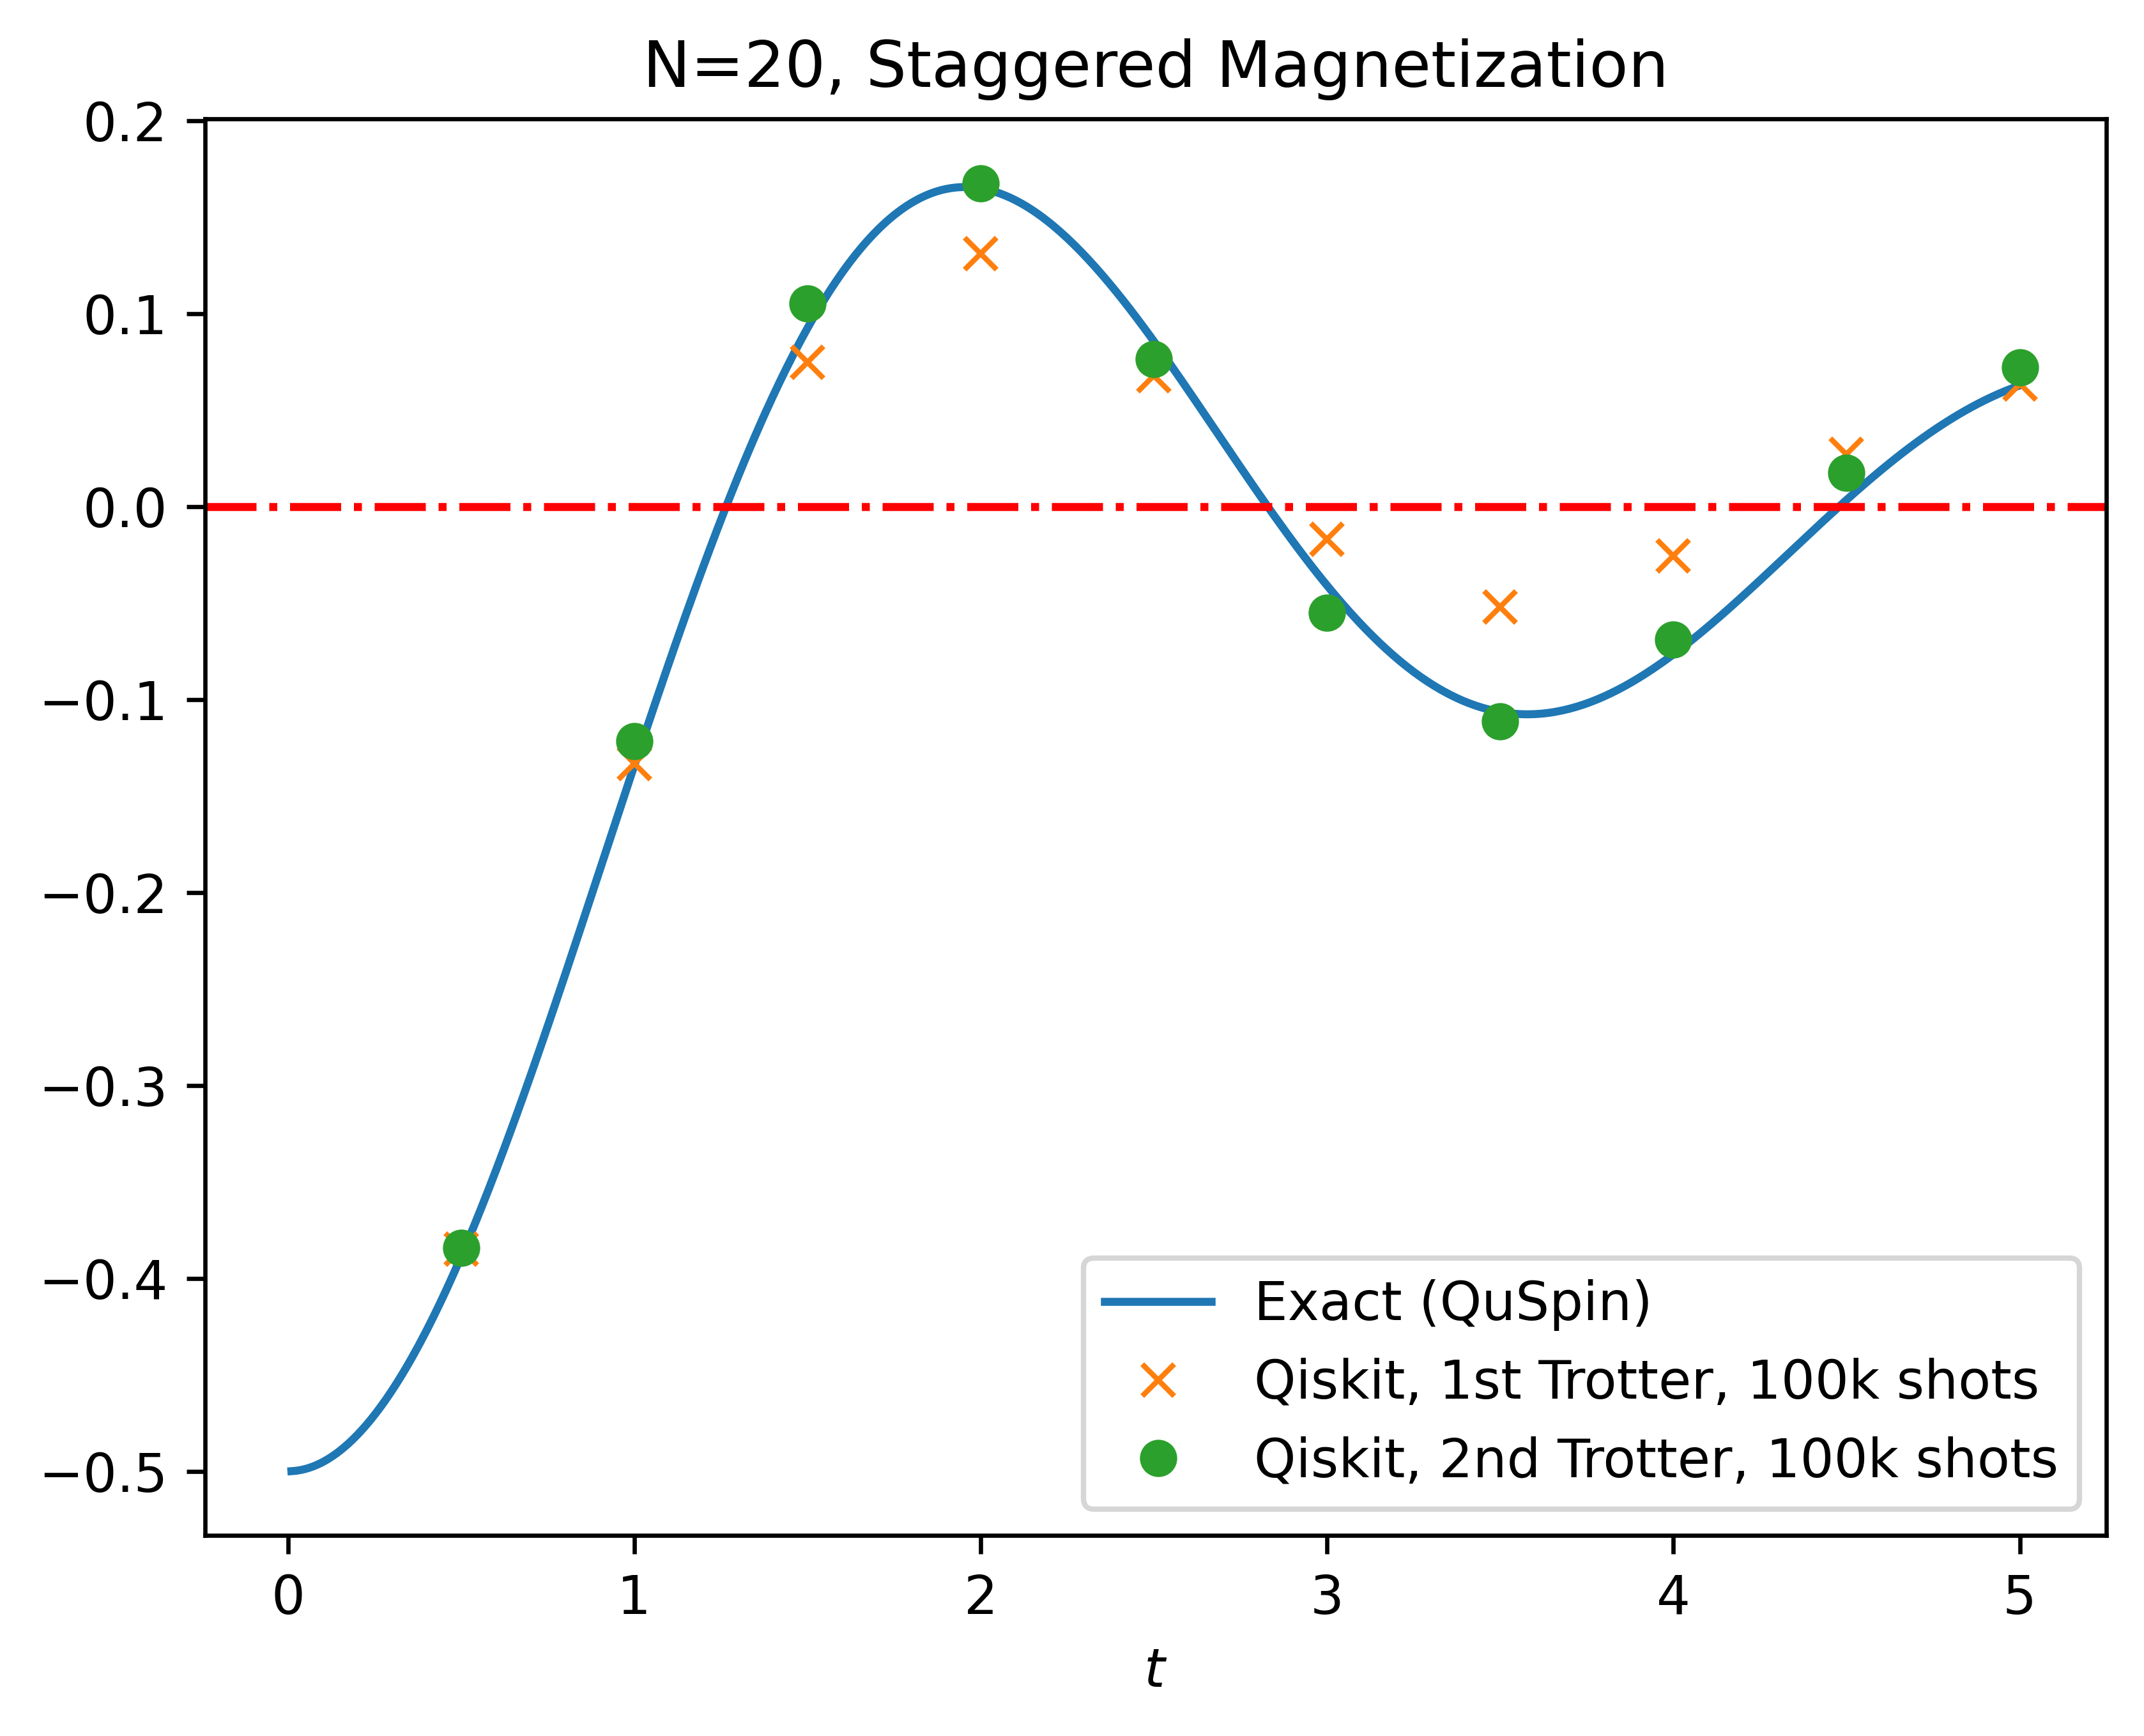

In [ ]:
plt.rcParams['figure.dpi']=600
plt.plot(x_exact,exp_quspin, label=f"Exact (QuSpin)")
plt.plot(x_qiskit,expList, 'x', label=f"Qiskit, 1st Trotter, 100k shots")
plt.plot(x_qiskit,expList2, 'o', label=f"Qiskit, 2nd Trotter, 100k shots")

plt.axhline(y=0.0, color='r', linestyle='-.')

#plt.autoscale(False)
#plt.ylim(-1.329, -1.328)
plt.xlabel("$t$")
plt.title(f'N={N}, Staggered Magnetization')
plt.legend()
plt.show()